In [7]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr, spearmanr
import seaborn as sns
import matplotlib.pyplot as plt

In [8]:
# Ustawienia estetyczne wykresów pod pracę inżynierską
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style="whitegrid", font_scale=1.05)

# 1. Wczytanie i oczyszczenie danych
csv_path = "../results/tables/baza_kalibracyjna_UAV_PlanetScope_FVC.csv"
df = pd.read_csv(csv_path)
df = df.replace([np.inf, -np.inf], np.nan).dropna().copy()

# Odfiltrowanie anomalii radiometrycznych
norm_indices = ['NDVI', 'SAVI', 'RENDVI', 'NDWI', 'PRI']
for idx in norm_indices:
    for prefix in ['UAV_', 'PS_']:
        col = f"{prefix}{idx}"
        if col in df.columns:
            df = df[(df[col] >= -1.0) & (df[col] <= 1.0)]

df = df[(df['UAV_EVI'].between(-1.0, 3.0)) & (df['PS_EVI'].between(-1.0, 3.0))]
df = df[(df['UAV_CIre'].between(-1.0, 15.0)) & (df['PS_CIre'].between(-1.0, 15.0))]
df = df.reset_index(drop=True)

print(f"Liczba czystych oczek 3x3 m do analizy korelacji: {len(df)}")

# 2. Kontrola skali po poszczególnych terminach nalotów
print("\n--- KONTROLA ŚREDNICH WARTOŚCI W TERMINACH (Sprawdź UAV_SAVI i UAV_EVI!) ---")
diag = df.groupby('flight_date')[['FVC', 'UAV_NDVI', 'PS_NDVI', 'UAV_SAVI', 'PS_SAVI', 'UAV_EVI', 'PS_EVI']].mean().round(3)
display(diag)

Liczba czystych oczek 3x3 m do analizy korelacji: 14775

--- KONTROLA ŚREDNICH WARTOŚCI W TERMINACH (Sprawdź UAV_SAVI i UAV_EVI!) ---


,FVC,UAV_NDVI,PS_NDVI,UAV_SAVI,PS_SAVI,UAV_EVI,PS_EVI
flight_date,,,,,,,
2026-09-02,0.969,0.580,0.724,0.635,0.508,0.735,0.559
2026-09-09,0.960,0.522,0.721,0.561,0.520,0.624,0.547
2026-09-15,0.964,0.466,0.723,0.545,0.481,0.631,0.514
2026-10-01,0.914,0.438,0.722,0.508,0.481,0.553,0.509
2026-10-03,0.952,0.411,0.714,0.438,0.491,0.443,0.527
2026-10-06,0.910,0.437,0.716,0.540,0.477,0.601,0.483


In [9]:
INDICES = ['NDVI','SAVI','EVI','RENDVI','CIre','NDWI','PRI']

wyniki_1do1 = []

for idx in INDICES:
    uav_col = f"UAV_{idx}"
    ps_col = f"PS_{idx}"
    r_val, p_pearson = pearsonr(df[ps_col], df[uav_col])
    rho_val, p_spearman  = spearmanr(df[ps_col],df[uav_col])
    wyniki_1do1.append({
        'Wskaźnik': idx,
        'Pearson (r)' : round(r_val, 4),
        'Spearman (rho)' :round(rho_val, 4),
        'Różnica (rho-r)' : round(rho_val - r_val, 4),   
        'Istotność (p < 0.001)': 'Tak' if (p_pearson < 0.001 and p_spearman < 0.001) else 'Nie'  })

df_1do1 = pd.DataFrame(wyniki_1do1)
display(df_1do1)

,Wskaźnik,Pearson (r),Spearman (rho),Różnica (rho-r),Istotność (p < 0.001)
0,NDVI,0.6554,0.6632,0.0078,Tak
1,SAVI,0.6375,0.6375,-0.0000,Tak
2,EVI,0.6212,0.6163,-0.0049,Tak
3,RENDVI,0.7778,0.7696,-0.0083,Tak
4,CIre,0.7787,0.7855,0.0069,Tak
5,NDWI,0.6642,0.6599,-0.0043,Tak
6,PRI,0.3361,0.3220,-0.0141,Tak


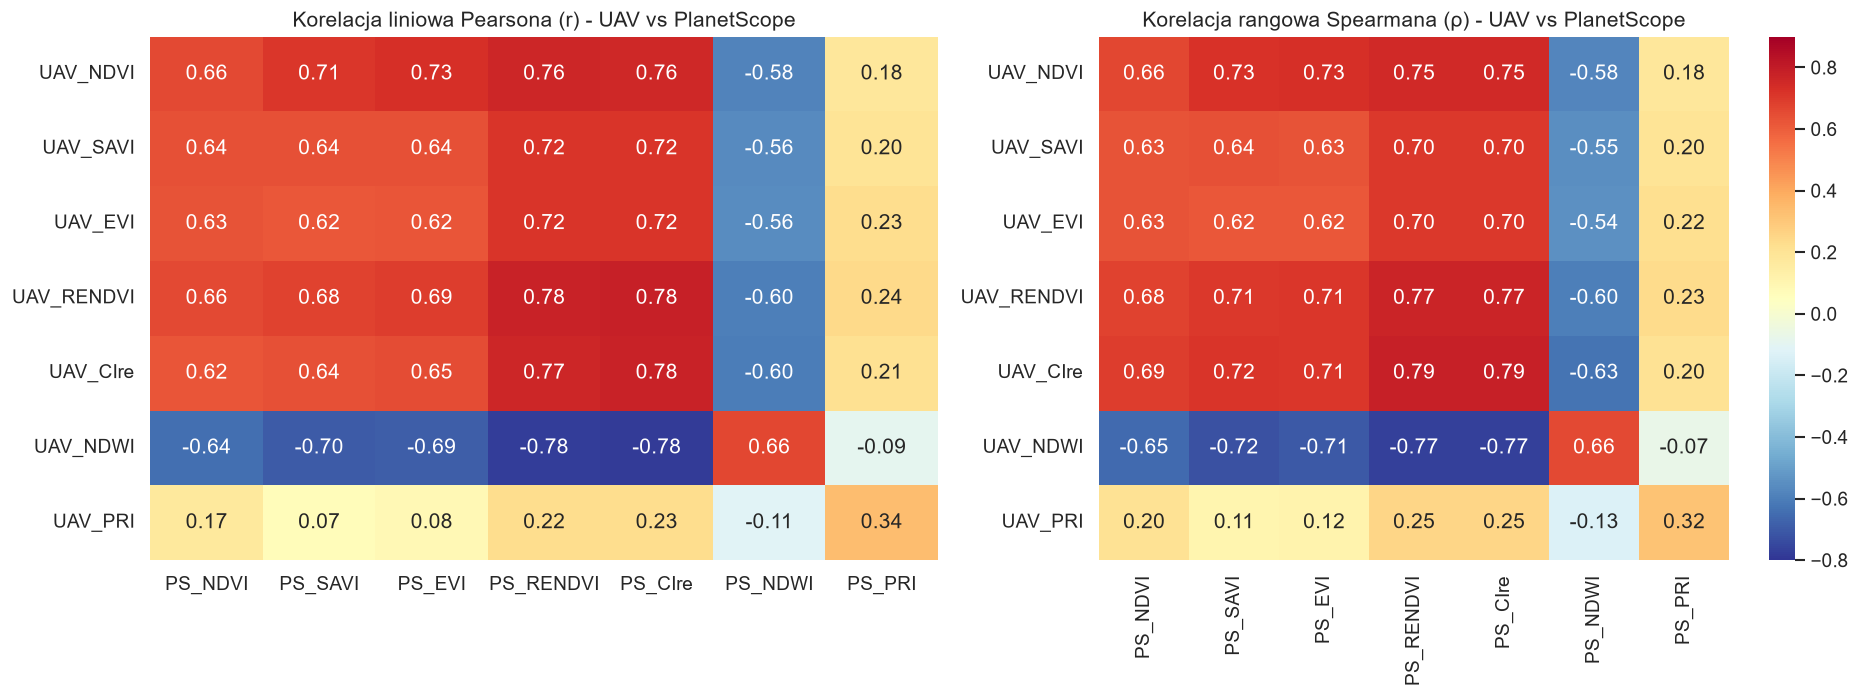

In [10]:
uav_cols = [f"UAV_{idx}" for idx in INDICES]
ps_cols  = [f"PS_{idx}" for idx in INDICES] 

corr_pearson = df[uav_cols + ps_cols].corr(method='pearson').loc[uav_cols, ps_cols]
corr_spearman = df[uav_cols + ps_cols].corr(method='spearman').loc[uav_cols, ps_cols]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="RdYlBu_r", vmin=-0.8, vmax=0.9, ax=axes[0], cbar=False)
axes[0].set_title("Korelacja liniowa Pearsona (r) - UAV vs PlanetScope")

sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="RdYlBu_r", vmin=-0.8, vmax=0.9, ax=axes[1])
axes[1].set_title("Korelacja rangowa Spearmana (ρ) - UAV vs PlanetScope")

plt.tight_layout()
plt.savefig("../results/correlation/wykres_heatmap_korelacje_krzyzowe.png", dpi=300)
plt.show()



Korelacja Pearsona (1 do 1) w poszczególnych terminach nalotów:


,Liczba_oczek,NDVI,SAVI,EVI,RENDVI,CIre,NDWI,PRI
flight_date,,,,,,,,
2026-09-02,2859,0.759,0.683,0.674,0.772,0.762,0.782,0.123
2026-09-09,2422,0.757,0.672,0.671,0.766,0.760,0.769,0.003
2026-09-15,2715,0.682,0.696,0.684,0.760,0.739,0.745,0.097
2026-10-01,2705,0.736,0.682,0.661,0.750,0.741,0.792,0.026
2026-10-03,2703,0.730,0.664,0.649,0.754,0.748,0.779,-0.005
2026-10-06,1371,0.764,0.605,0.601,0.837,0.849,0.827,0.060


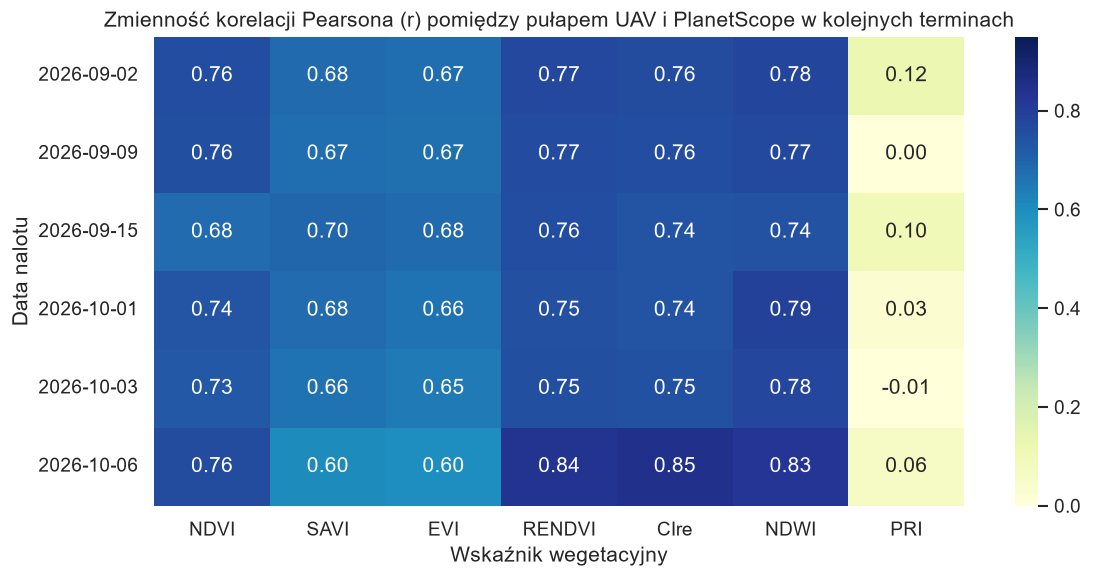

In [11]:
korelacje_czasowe = []
for dt, group in df.groupby('flight_date'):
    row_dict = {'flight_date': dt, 'Liczba_oczek': len(group)}
    for idx in INDICES:
        r_dt, _ = pearsonr(group[f"PS_{idx}"], group[f"UAV_{idx}"])
        row_dict[idx] = round(r_dt, 3)
    korelacje_czasowe.append(row_dict)

df_kor_czas = pd.DataFrame(korelacje_czasowe).set_index('flight_date')
df_kor_czas.to_csv("tabela_korelacje_po_terminach.csv")

print("\nKorelacja Pearsona (1 do 1) w poszczególnych terminach nalotów:")
display(df_kor_czas)

# Wizualizacja korelacji po terminach jako mapa ciepła
plt.figure(figsize=(10, 5))
sns.heatmap(df_kor_czas[INDICES], annot=True, fmt=".2f", cmap="YlGnBu", vmin=0.0, vmax=0.95)
plt.title("Zmienność korelacji Pearsona (r) pomiędzy pułapem UAV i PlanetScope w kolejnych terminach")
plt.ylabel("Data nalotu")
plt.xlabel("Wskaźnik wegetacyjny")
plt.tight_layout()
plt.savefig("../results/correlation/wykres_korelacje_w_czasie.png", dpi=300)
plt.show()

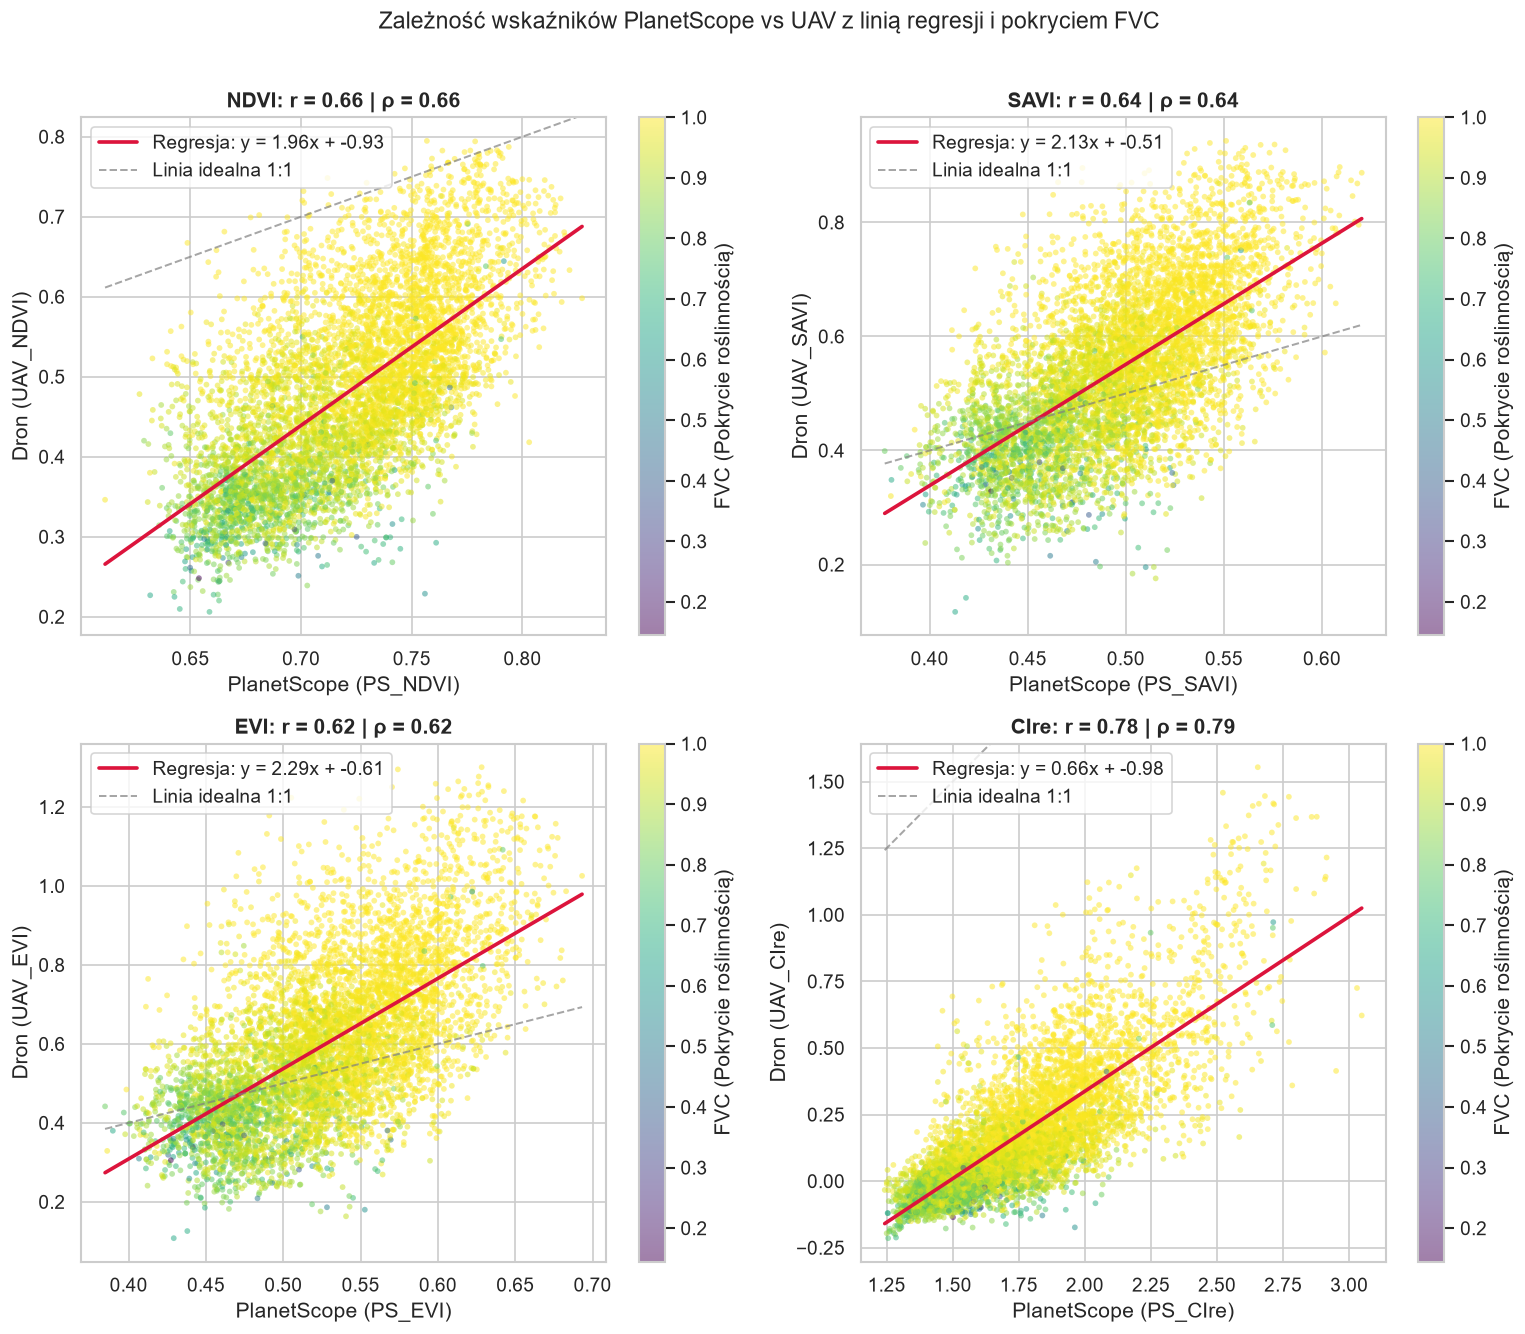

In [12]:
wybrane = ['NDVI', 'SAVI', 'EVI', 'CIre']
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
axes = axes.flatten()

# Losujemy próbkę np. 6000 punktów dla czytelności wykresu
df_plot = df.sample(n=min(6000, len(df)), random_state=42)

for i, idx in enumerate(wybrane):
    ax = axes[i]
    ps_col = f"PS_{idx}"
    uav_col = f"UAV_{idx}"
    
    x_vals = df_plot[ps_col]
    y_vals = df_plot[uav_col]
    
    # 1. Chmura punktów z kolorem od FVC
    sc = ax.scatter(
        x_vals, y_vals, 
        c=df_plot['FVC'], 
        cmap='viridis', 
        alpha=0.5, 
        s=12, 
        edgecolors='none'
    )
    
    # 2. Wyliczenie i narysowanie linii regresji liniowej (y = a*x + b) na pełnym zbiorze
    a, b = np.polyfit(df[ps_col], df[uav_col], 1)
    x_line = np.linspace(x_vals.min(), x_vals.max(), 100)
    ax.plot(x_line, a * x_line + b, color='crimson', linewidth=2.2, 
            label=f'Regresja: y = {a:.2f}x + {b:.2f}')
    
    # 3. Delikatna linia 1:1 w tle dla odniesienia (bez rozciągania osi wykresu)
    ax.plot(x_line, x_line, color='gray', linestyle='--', linewidth=1.2, alpha=0.7, 
            label='Linia idealna 1:1')
    
    # Dopasowanie zakresu osi ściśle do chmury punktów (z 5% marginesem)
    x_margin = (x_vals.max() - x_vals.min()) * 0.05
    y_margin = (y_vals.max() - y_vals.min()) * 0.05
    ax.set_xlim(x_vals.min() - x_margin, x_vals.max() + x_margin)
    ax.set_ylim(y_vals.min() - y_margin, y_vals.max() + y_margin)
    
    # 4. Wyliczenie Pearsona i Spearmana do tytułu
    r_val, _ = pearsonr(df[ps_col], df[uav_col])
    rho_val, _ = spearmanr(df[ps_col], df[uav_col])
    
    ax.set_title(f"{idx}: r = {r_val:.2f} | ρ = {rho_val:.2f}", fontweight='bold')
    ax.set_xlabel(f"PlanetScope ({ps_col})")
    ax.set_ylabel(f"Dron ({uav_col})")
    ax.legend(loc='upper left', frameon=True)
    plt.colorbar(sc, ax=ax, label='FVC (Pokrycie roślinnością)')

plt.suptitle("Zależność wskaźników PlanetScope vs UAV z linią regresji i pokryciem FVC", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig("../results/correlation/wykres_scatter_regresja_FVC.png", dpi=300, bbox_inches='tight')
plt.show()